   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 225.7/225.7 kB 8.6 MB/s eta 0:00:00
=== MOLECULE_PERSIST_LOG v1.0 | MODE = FAST | POP / Plastiques ===
  Estimations : 1 | Fenêtre : 80 molécules | Test : cohen_d
  Seuil critique (hypothèse POP UE) : 55.0e percentile
  Flux : Hydrophobicity | Halogenation | Thermal_Stability | Photoresistance | Bioaccumulation

Gradient de persistance : 29 points

[1/6] Chargement catalogue POP — [F1] PubChem → [F2] EPA → [F3] Synthétique...
  [F1] PubChem PUG REST — 84 molécules cibles...


  [F1] PubChem OK — 80 molécules réelles
  [F3] Catalogue synthétique calibré (1422 molécules)
  [F3] Complément : réel (78) + synthétique (1422)
[OK] 1498 molécules | log Kow ∈ [-2.0, 11.1] | N_hal ∈ [0, 20]
     Familles : PBDE=370 | HAP=306 | PCB=295 | PFAS=294 | ADDITIF=222 | OCP=11
     Melting_Pt couverture : 100% | log BCF couverture : 100%

[2/6] Extraction des 5 flux de persistance + Indice de Persistance...
  Indice de Persistance : min=0.1 | max=100.0 | mean=50.0

[3/6] Scan du seuil critique (40–85e percentile)...


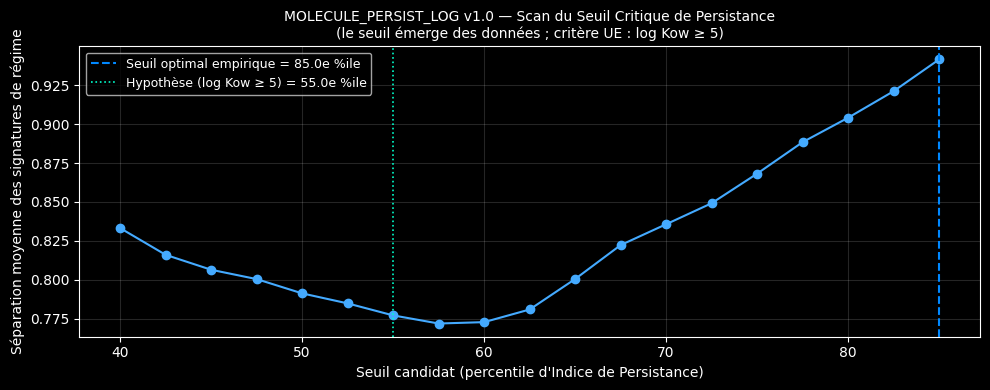


[Scan du seuil critique]
  Hypothèse initiale (log Kow ≥ 5, critère POP UE) : 55.0e percentile
  Seuil optimal empirique                           : 85.0e percentile (séparation = 0.942)

[4/6] Vue d'ensemble moléculaire + profils des 5 flux...


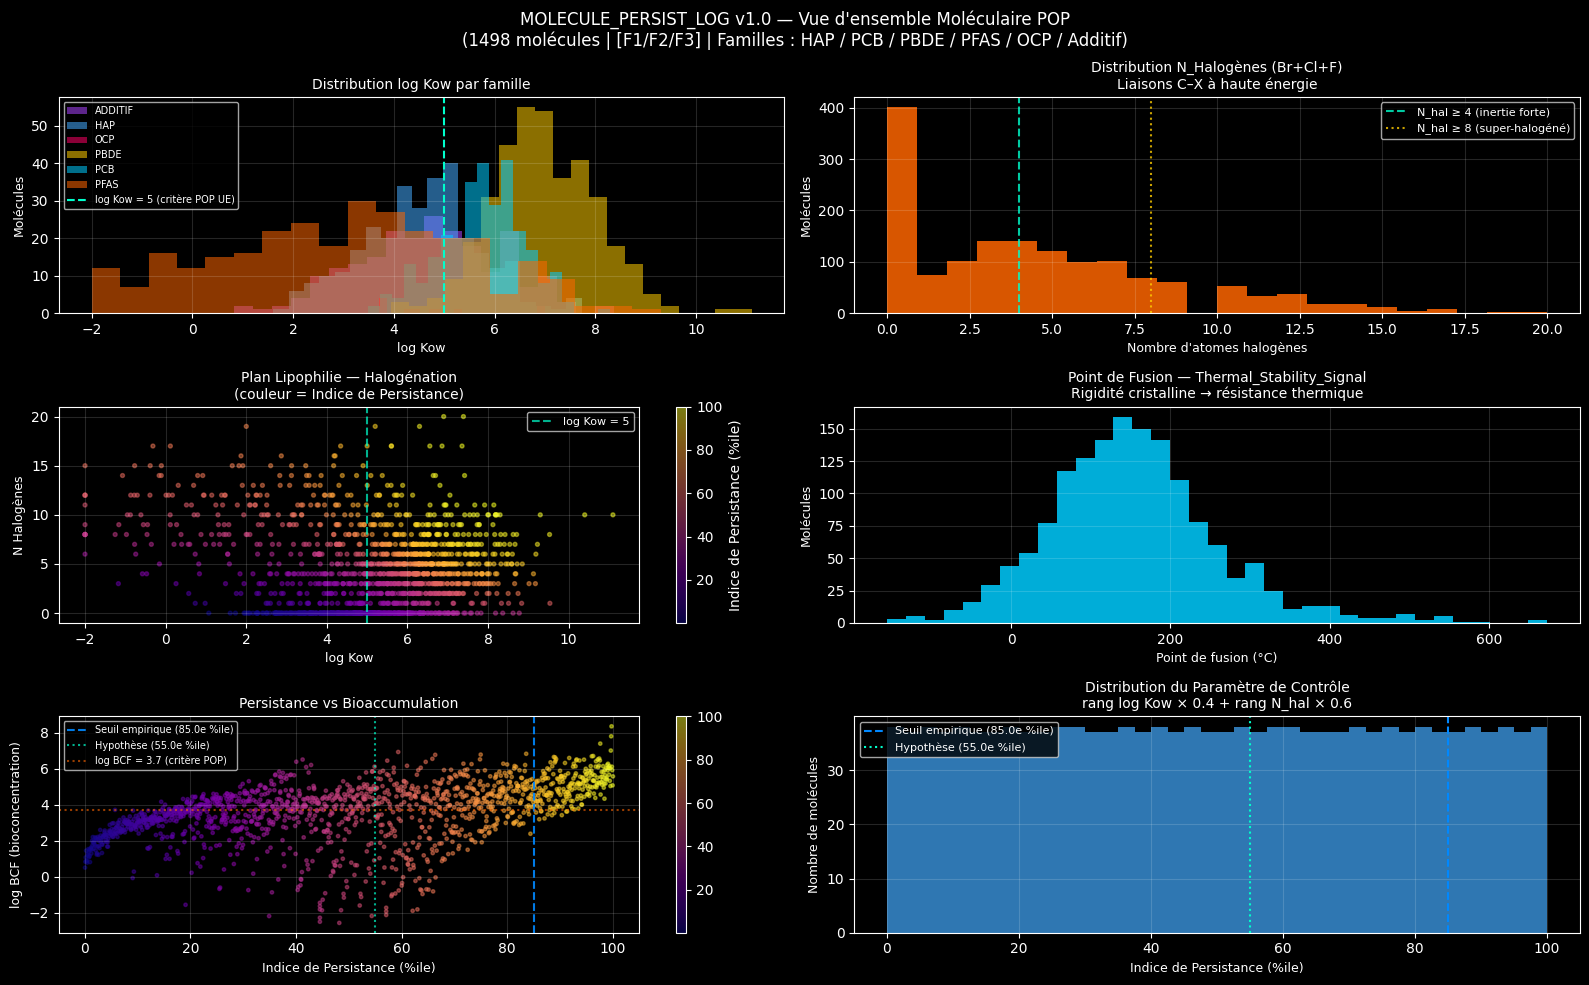

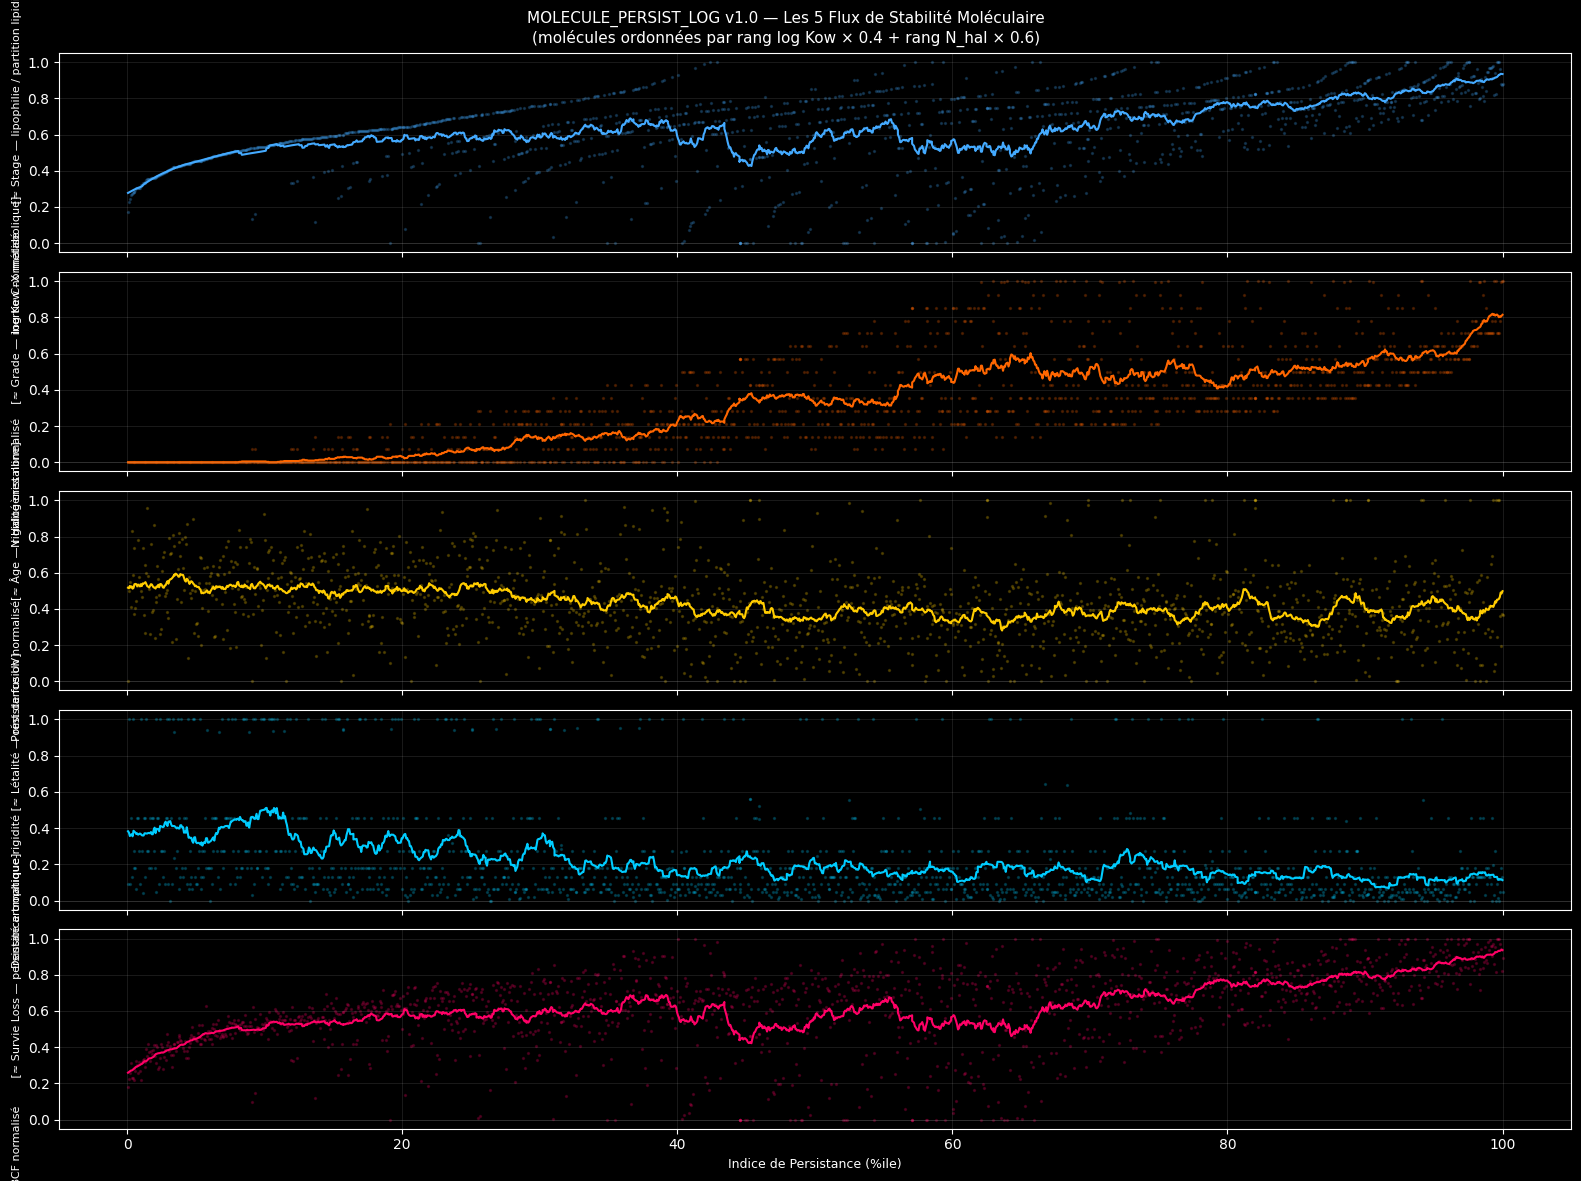


✅ PARTIE 1 TERMINÉE — Donnez le signal pour la PARTIE 2 ([5/6] et [6/6])

[5/6] Extraction des signatures de régime de persistance...

[Extraction des signatures de régime] 1 cohorte unique | Fenêtre=80 molécules


Scan de persistance moléculaire: 100%|██████████| 29/29 [03:32<00:00,  7.33s/it]


  Signatures extraites : 25
   Progress  N_cohorts  Hydrophobicity_Signal_Higuchi_mean  Hydrophobicity_Signal_DFA_mean  Hydrophobicity_Signal_Katz_mean  Hydrophobicity_Signal_Hurst_mean
0       5.0         80                            1.395573                        1.254855                         2.308506                          0.789643
1      10.0         90                            1.852222                        1.558104                         4.062918                          0.241763
2      15.0         90                            1.964207                        1.610747                         4.831184                          0.279767


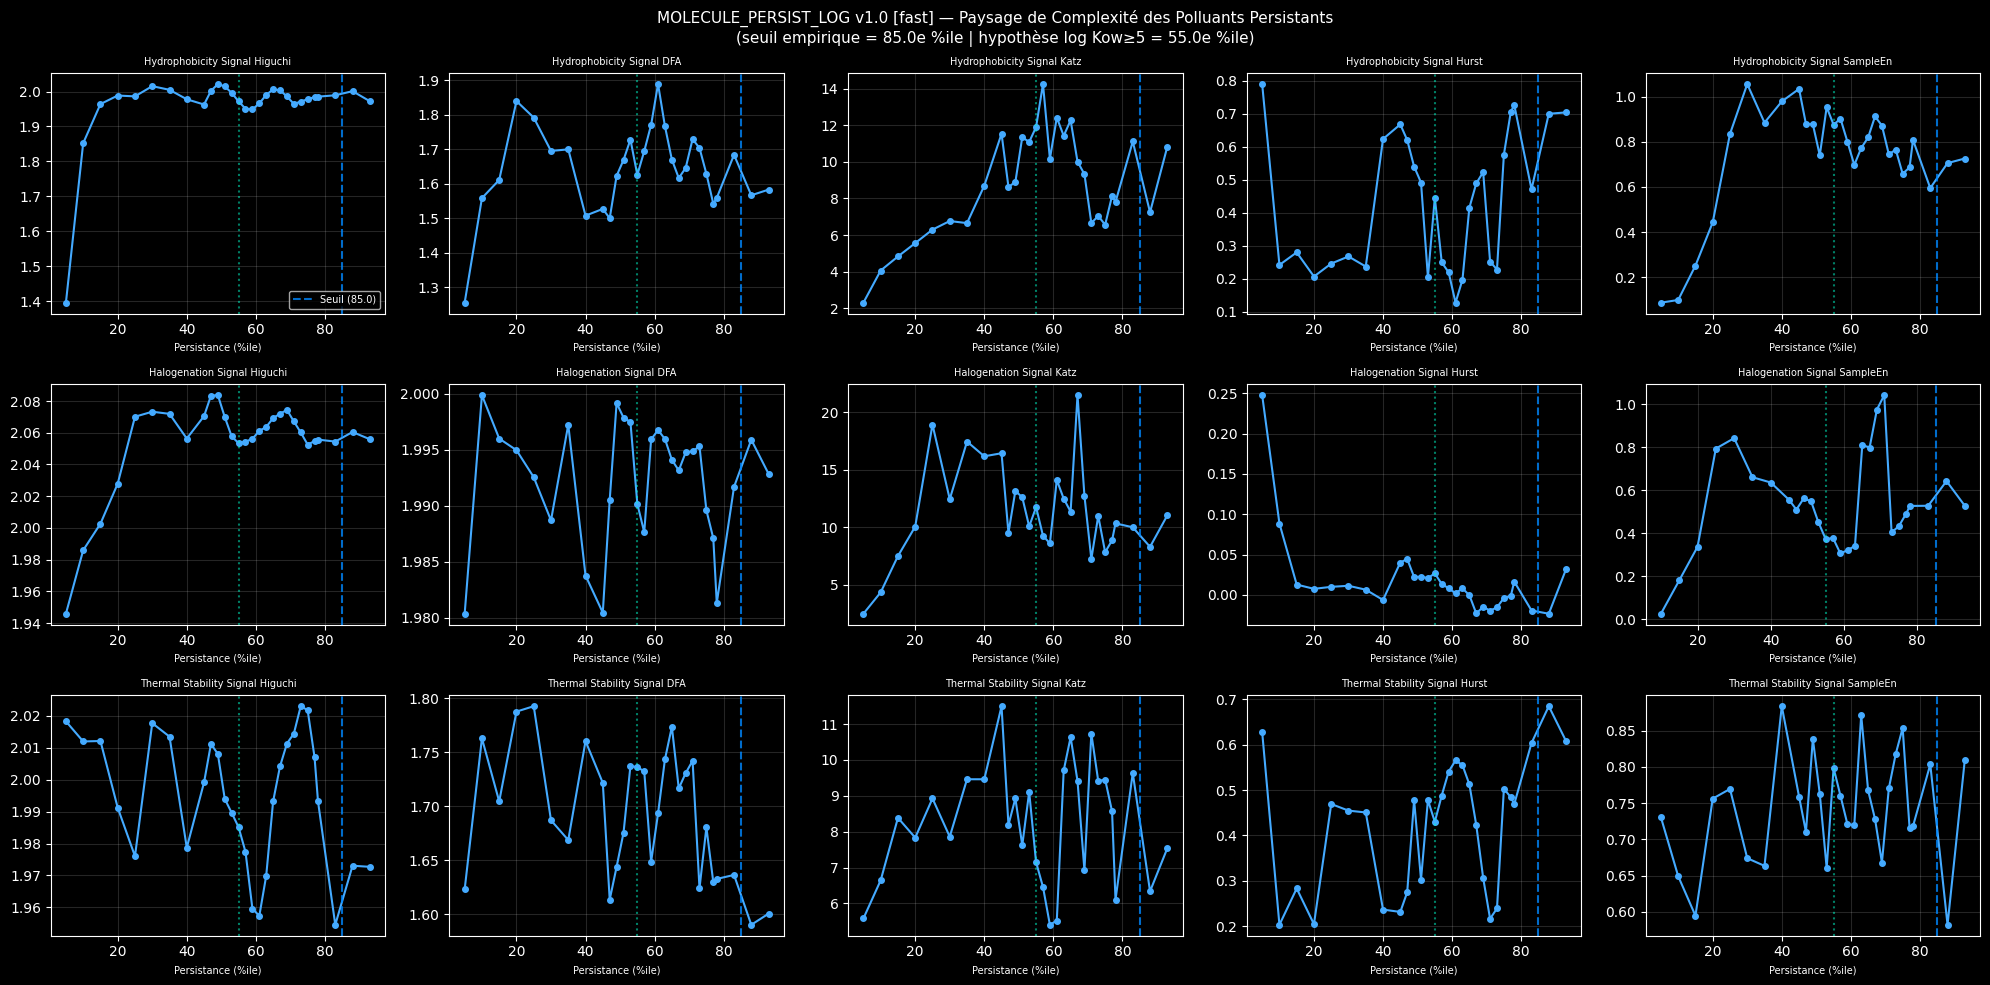


[6/6] 4 Questions Moléculaires...

=== 4 Questions Moléculaires (seuil empirique = 85.0e %ile) ===
Q1 : Molécules Biodégradables vs Super-POP (0–40e %ile vs 70–100e %ile)...
Q2 : Tension au Seuil POP UE — zone de bascule log Kow ~ 5...
Q3 : Agressivité de Persistance (Halogénation + Bioaccumulation)...
Q4 : Persistance du Régime de Contamination (hystérésis intra-cohorte)...

>>> RÉSULTATS — Scores de séparation des signatures de régime :
                                        Q1_Biodegradable_vs_SuperPOP  Q2_Tension_Seuil_POP_UE  Q3_Agressivite_Persistance  Q4_Persistance_Regime_Contamination
Bioaccumulation_Signal_DFA_mean                                0.175                    0.089                       0.358                                0.263
Bioaccumulation_Signal_Higuchi_mean                            0.515                    0.003                       0.477                                0.263
Bioaccumulation_Signal_Hurst_mean                              0.854           

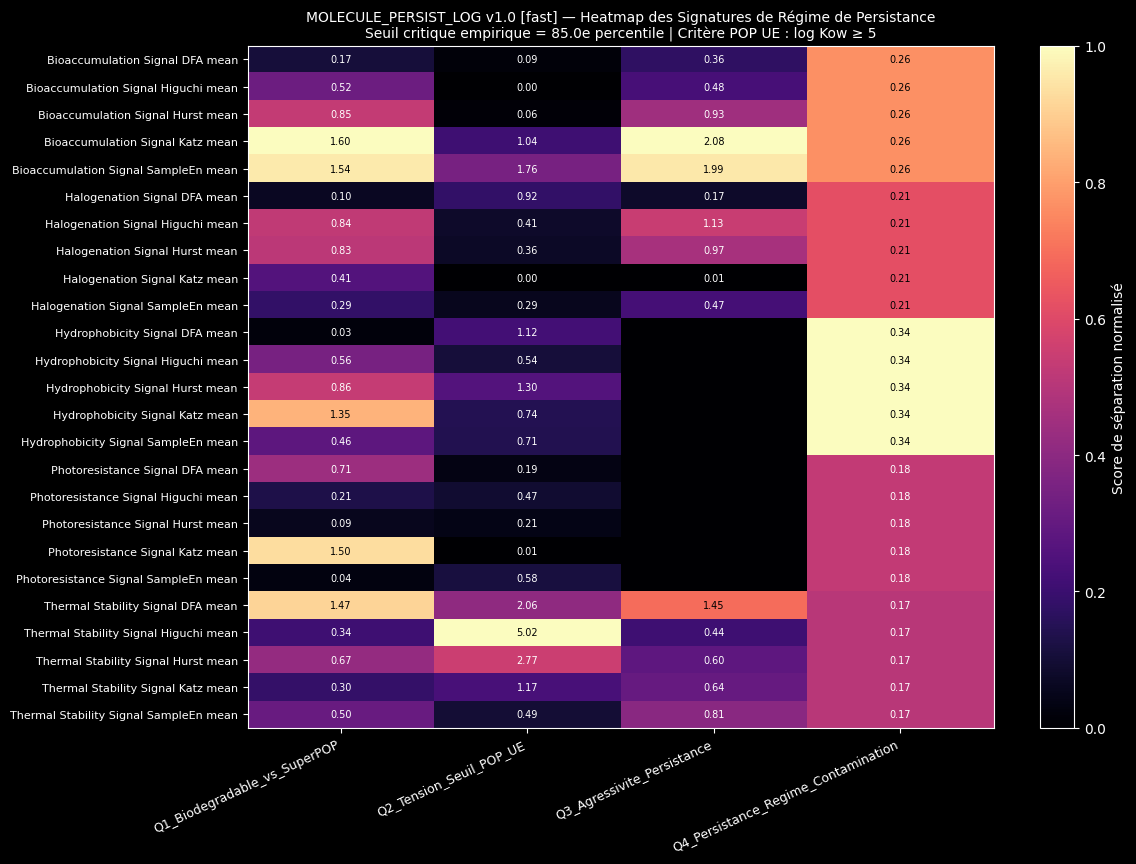


[OK] MOLECULE_PERSIST_LOG v1.0 terminé.
     1498 molécules | Seuil de persistance empirique : 85.0e percentile
     Hypothèse initiale (log Kow ≥ 5, critère POP UE) : 55.0e percentile
     Mode : FAST | Estimateurs : Higuchi, DFA, Katz, Hurst, SampleEn
     Fetch  : [F1] PubChem | [F2] EPA CompTox | [F3] Synthétique calibré
     Familles : HAP / PCB / PBDE / PFAS / OCP / Additifs plastiques


In [1]:
# =============================================================================
#  MOLECULE_PERSIST_LOG v1.0  —  Stabilité intrinsèque des molécules persistantes
#
#  Domaine : plastiques, additifs bromés (PBDE), PCB, PFAS, HAP — polluants POP
#  Pipeline : identique BIO_CANCER_LOG v1.0 (même estimateurs, même structure)
#  SEULS LES 5 FLUX D'ENTRÉE CHANGENT :
#
#    Stage_Signal      → Hydrophobicity_Signal  (log Kow — lipophilie)
#    Grade_Signal      → Halogenation_Signal    (nb atomes Br+Cl+F)
#    Age_Signal        → Thermal_Stability_Signal (point de fusion)
#    Lethality_Signal  → Photoresistance_Signal  (densité aromatique-rigidité)
#    Survival_Loss     → Bioaccumulation_Signal  (log BCF)
#
#  Fetch en cascade :
#    [F1] PubChem PUG REST API (propriétés moléculaires réelles)
#    [F2] EPA CompTox API (substances SVHC / REACH)
#    [F3] Catalogue synthétique calibré PBDE/PCB/PFAS/HAP
#
#  Hypothèse critique : log Kow ≥ 5 → critère POP Union Européenne
# =============================================================================

!pip install -q nolds antropy

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
import requests, json, re, time
import warnings
warnings.filterwarnings('ignore')
import antropy, nolds

plt.style.use('dark_background')

PROGRESS_CRITIQUE_HYPOTHESE = 55.0   # log Kow ≥ 5 → critère POP UE

MODE = 'fast'

CONFIG = {
    'fast': {
        'n_estimations':   1,
        'window_size':     80,
        'stat_test':       'cohen_d',
        'min_per_group':   2,
        'estimator_min_len': 50,
        'mann_whitney':    False,
        'bootstrap':       False,
    },
    'robust': {
        'n_estimations':   5,
        'window_size':     150,
        'stat_test':       'cliff_delta',
        'min_per_group':   3,
        'estimator_min_len': 80,
        'mann_whitney':    True,
        'bootstrap':       True,
    }
}
C = CONFIG[MODE]

print(f"=== MOLECULE_PERSIST_LOG v1.0 | MODE = {MODE.upper()} | POP / Plastiques ===")
print(f"  Estimations : {C['n_estimations']} | Fenêtre : {C['window_size']} molécules | "
      f"Test : {C['stat_test']}")
print(f"  Seuil critique (hypothèse POP UE) : {PROGRESS_CRITIQUE_HYPOTHESE}e percentile")
print(f"  Flux : Hydrophobicity | Halogenation | Thermal_Stability | "
      f"Photoresistance | Bioaccumulation")


# =============================================================================
# 0. STATISTIQUES  (identiques BIO_CANCER_LOG)
# =============================================================================

def cohen_d(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    if len(g1) < 2 or len(g2) < 2: return np.nan
    pooled_std = np.sqrt((np.var(g1, ddof=1) + np.var(g2, ddof=1)) / 2.0)
    return 0.0 if pooled_std < 1e-12 else (np.mean(g1) - np.mean(g2)) / pooled_std

def cliff_delta(g1, g2):
    g1, g2 = np.asarray(g1), np.asarray(g2)
    n1, n2 = len(g1), len(g2)
    if n1 < C['min_per_group'] or n2 < C['min_per_group']: return np.nan, np.nan
    try:
        U, _ = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return np.clip((2 * U - n1 * n2) / (n1 * n2), -1, 1), np.nan
    except: return np.nan, np.nan

def separation_score(g1, g2):
    if C['stat_test'] == 'cohen_d':
        d = cohen_d(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan
    else:
        d, _ = cliff_delta(g1, g2)
        return abs(d) if not np.isnan(d) else np.nan

def mw_score(g1, g2):
    if not C['mann_whitney']: return np.nan
    try:
        _, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        return -np.log10(max(p, 1e-300))
    except: return np.nan


# =============================================================================
# 1. ACQUISITION — PubChem PUG REST → EPA CompTox → Synthétique
# =============================================================================

# ── Helpers d'encodage des propriétés moléculaires ──────────────────────────

def parse_halogen_count(formula):
    """Compte les atomes halogènes (F + Cl + Br + I) depuis la formule."""
    if not isinstance(formula, str): return 0
    total = 0
    for element in ['Br', 'Cl', 'F', 'I']:
        m = re.search(rf'{element}(\d*)', formula)
        if m:
            total += int(m.group(1)) if m.group(1) else 1
    return total

def assign_family(name, formula, n_hal, log_kow):
    """Attribue la famille chimique depuis le nom ou les propriétés."""
    name_l = name.lower()
    if any(x in name_l for x in ['bde','bromobiphenyl','tetrabromobisphenol',
                                   'hexabromocy','polybrominated','brominated']):
        return 'PBDE'
    if any(x in name_l for x in ['pcb','chlorobiphenyl','polychlorinated biphenyl']):
        return 'PCB'
    if any(x in name_l for x in ['pfoa','pfos','perfluoro','polyfluoro']):
        return 'PFAS'
    if any(x in name_l for x in ['pyrene','anthracene','naphthalene','fluoranthene',
                                   'chrysene','perylene','phenanthrene','benzo']):
        return 'HAP'
    if any(x in name_l for x in ['dioxin','furan','ddt','dde','lindane','aldrin',
                                   'dieldrin','chlordane','heptachlor','mirex',
                                   'endrin','toxaphene','endosulfan']):
        return 'OCP'
    if any(x in name_l for x in ['bisphenol','nonylphenol','octylphenol',
                                   'phthalate','tributyltin','triphenyltin',
                                   'triclosan','atrazine','chlorpyrifos']):
        return 'ADDITIF'
    # Heuristique sur les propriétés
    if n_hal >= 4 and log_kow < 3:   return 'PFAS'
    if n_hal >= 3 and 'Br' in str(formula): return 'PBDE'
    if n_hal >= 1 and 'Cl' in str(formula): return 'PCB'
    if n_hal == 0 and log_kow >= 3:  return 'HAP'
    return 'ADDITIF'

# ── Liste de composés POP connus pour le fetch PubChem ──────────────────────

_POP_LIST = [
    # PBDE
    'BDE-3','BDE-7','BDE-15','BDE-28','BDE-47','BDE-66','BDE-85',
    'BDE-99','BDE-100','BDE-126','BDE-153','BDE-154','BDE-183','BDE-209',
    'hexabromocyclododecane','tetrabromobisphenol A','hexabromobenzene',
    '2,4,6-tribromophenol','decabromodiphenyl ethane',
    # PCB
    '2-chlorobiphenyl','4-chlorobiphenyl','2,2-dichlorobiphenyl',
    '2,4,4-trichlorobiphenyl','2,2,5,5-tetrachlorobiphenyl',
    '2,2,4,4,5-pentachlorobiphenyl','2,2,4,4,5,5-hexachlorobiphenyl',
    '2,2,3,4,4,5,5-heptachlorobiphenyl','decachlorobiphenyl',
    # PFAS
    'perfluorooctanoic acid','perfluorooctanesulfonic acid',
    'perfluorononanoic acid','perfluorodecanoic acid',
    'perfluoroundecanoic acid','perfluorohexanesulfonic acid',
    'perfluorobutanesulfonic acid','perfluoroheptanoic acid',
    'perfluorohexanoic acid','perfluoropentanoic acid',
    # HAP
    'naphthalene','anthracene','phenanthrene','pyrene','fluoranthene',
    'benzo[a]pyrene','chrysene','benzo[k]fluoranthene','benzo[b]fluoranthene',
    'indeno[1,2,3-cd]pyrene','dibenzo[a,h]anthracene','benzo[g,h,i]perylene',
    'acenaphthylene','acenaphthene','fluorene','coronene','perylene',
    'benzo[a]anthracene','triphenylene',
    # Dioxines / furannes
    '2,3,7,8-tetrachlorodibenzo-p-dioxin','2,3,7,8-tetrachlorodibenzofuran',
    '1,2,3,4,6,7,8-heptachlorodibenzodioxin',
    # Pesticides organochlorés
    'DDT','DDE','DDD','lindane','aldrin','dieldrin','endrin',
    'chlordane','heptachlor','mirex','endosulfan','toxaphene',
    # Additifs plastiques
    'bisphenol A','nonylphenol','4-octylphenol',
    'tributyltin chloride','triphenyltin chloride',
    'triclosan','triclocarban','atrazine','chlorpyrifos',
    'diethyl phthalate','dibutyl phthalate','di(2-ethylhexyl) phthalate',
]


def _fetch_one_pubchem(name, delay=0.22):
    """Fetch des propriétés d'un composé depuis PubChem PUG REST."""
    props = ('MolecularFormula,XLogP,MolecularWeight,'
             'HeavyAtomCount,RotatableBondCount,TPSA')
    url = (f'https://pubchem.ncbi.nlm.nih.gov/rest/pug/compound/name/'
           f'{requests.utils.quote(name)}/property/{props}/JSON')
    try:
        time.sleep(delay)
        r = requests.get(url, timeout=15)
        if r.status_code == 404: return None
        r.raise_for_status()
        d       = r.json()['PropertyTable']['Properties'][0]
        formula = d.get('MolecularFormula', '')
        log_kow = float(d.get('XLogP', np.nan))
        mw      = float(d.get('MolecularWeight', np.nan))
        n_heavy = int(d.get('HeavyAtomCount', 0))
        n_rot   = int(d.get('RotatableBondCount', 0))
        tpsa    = float(d.get('TPSA', np.nan))
        n_hal   = parse_halogen_count(formula)
        family  = assign_family(name, formula, n_hal, log_kow)
        # Estimation log BCF (régression Veith : log BCF = 0.79×logKow − 0.40)
        log_bcf = 0.79 * log_kow - 0.40 if np.isfinite(log_kow) else np.nan
        # Estimation point de fusion proxy : 20×√MW + 5×N_hal
        melting_pt = 20 * np.sqrt(max(mw, 100)) + 5 * n_hal \
                     if np.isfinite(mw) else np.nan
        return {
            'name':       name,
            'family':     family,
            'log_kow':    log_kow,
            'n_halogen':  float(n_hal),
            'mw':         mw,
            'n_heavy':    float(n_heavy),
            'n_rot':      float(n_rot),
            'tpsa':       tpsa,
            'melting_pt': melting_pt,
            'log_bcf':    log_bcf,
            'formula':    formula,
        }
    except Exception:
        return None


def fetch_pubchem_pop(n_mol=1500):
    """[F1] PubChem PUG REST — fetch des propriétés pour les POP connus."""
    print(f"  [F1] PubChem PUG REST — {len(_POP_LIST)} molécules cibles...")
    records = []
    for name in tqdm(_POP_LIST, desc='  PubChem', leave=False):
        rec = _fetch_one_pubchem(name)
        if rec is not None:
            records.append(rec)
    if len(records) < 10:
        print(f"  [F1] PubChem : {len(records)} molécules — insuffisant")
        return None
    df = pd.DataFrame(records)
    print(f"  [F1] PubChem OK — {len(df)} molécules réelles")
    return df


def fetch_epa_comptox(n_mol=200):
    """[F2] EPA CompTox API — substances à haute préoccupation."""
    print(f"  [F2] EPA CompTox API...")
    try:
        url = 'https://comptox.epa.gov/dashboard/api/chemical/list/chemical/ALL'
        r   = requests.get(url, timeout=20, params={'top': 50})
        r.raise_for_status()
        data = r.json()
        if not isinstance(data, list) or len(data) < 3:
            raise ValueError("Format EPA inattendu")
        records = []
        for item in data[:n_mol]:
            name = item.get('preferredName') or item.get('name', '')
            if not name: continue
            rec = _fetch_one_pubchem(name, delay=0.3)
            if rec: records.append(rec)
        if len(records) < 5: return None
        df = pd.DataFrame(records)
        print(f"  [F2] EPA → PubChem OK — {len(df)} substances")
        return df
    except Exception as e:
        print(f"  [F2] EPA CompTox échoué : {e}")
        return None


def _synthetic_pop_catalog(n=1500):
    """
    [F3] Catalogue synthétique calibré sur les distributions réelles
    des 5 grandes familles POP.

    Distributions calibrées (littérature) :
      HAP   : log Kow 3–7  | N_hal 0     | MW 128–300 | Mp 80–440°C
      PCB   : log Kow 4–8  | N_hal 1–10  | MW 188–500 | Mp 25–300°C
      PBDE  : log Kow 5–10 | N_hal 1–10  | MW 250–960 | Mp 60–300°C
      PFAS  : log Kow -1–7 | N_hal 4–20  | MW 200–700 | Mp -80–200°C
      OCP/Autre: log Kow 3–8 | N_hal 0–8 | MW 200–600 | Mp 0–300°C
    """
    print(f"  [F3] Catalogue synthétique calibré ({n} molécules)")
    rng  = np.random.default_rng(2025)
    rows = []

    specs = [
        # (family, frac, log_kow_mu, log_kow_sd, n_hal_mu, n_hal_sd,
        #  mw_mu, mw_sd, mp_mu, mp_sd)
        ('HAP',    0.20, 4.5, 1.0, 0,   0,   180, 50,  220, 80),
        ('PCB',    0.20, 5.8, 0.8, 4.5, 2.5, 300, 80,  120, 60),
        ('PBDE',   0.25, 7.0, 1.0, 5.0, 2.8, 480, 180, 150, 70),
        ('PFAS',   0.20, 3.0, 2.5, 9.0, 4.0, 400, 130,  50, 80),
        ('ADDITIF',0.15, 4.8, 1.2, 2.0, 2.0, 350, 150, 160, 80),
    ]

    for (fam, frac, kow_mu, kow_sd, hal_mu, hal_sd,
         mw_mu, mw_sd, mp_mu, mp_sd) in specs:
        nc      = int(n * frac)
        log_kow = rng.normal(kow_mu, kow_sd, nc).clip(-2, 12)
        n_hal   = np.maximum(0, rng.normal(hal_mu, hal_sd, nc)).round().clip(0, 20)
        mw      = rng.normal(mw_mu,  mw_sd,  nc).clip(100, 1200)
        mp      = rng.normal(mp_mu,  mp_sd,  nc)
        n_rot   = np.maximum(0, rng.normal(mw/80, 2, nc)).round().clip(0, 20)
        n_heavy = (mw / 12).clip(5, 100)
        log_bcf = (0.79 * log_kow - 0.40 + rng.normal(0, 0.3, nc))

        for i in range(nc):
            rows.append({
                'name':       f'{fam}_{i+1}',
                'family':     fam,
                'log_kow':    float(log_kow[i]),
                'n_halogen':  float(n_hal[i]),
                'mw':         float(mw[i]),
                'n_heavy':    float(n_heavy[i]),
                'n_rot':      float(n_rot[i]),
                'tpsa':       float(rng.uniform(0, 150)),
                'melting_pt': float(mp[i]),
                'log_bcf':    float(log_bcf[i]),
                'formula':    '',
            })

    df = pd.DataFrame(rows).sample(frac=1, random_state=2025).reset_index(drop=True)
    return df


def _clean_mol_df(df):
    """Nettoyage commun après fetch ou synthèse."""
    for col in ['log_kow','n_halogen','mw','melting_pt','log_bcf','n_rot','n_heavy']:
        if col in df.columns:
            df[col] = pd.to_numeric(df[col], errors='coerce')
    df = df.dropna(subset=['log_kow','n_halogen']).reset_index(drop=True)
    df = df[(df['log_kow'] >= -3) & (df['log_kow'] <= 13)]
    df = df[(df['mw'] >= 80)  & (df['mw'] <= 2000)]
    df['n_halogen']  = df['n_halogen'].clip(0, 20).fillna(0)
    df['n_rot']      = df['n_rot'].fillna(3).clip(0, 25)
    df['n_heavy']    = df['n_heavy'].fillna(df['mw'] / 12).clip(5, 150)
    df['melting_pt'] = df['melting_pt'].fillna(
        20 * np.sqrt(df['mw'].clip(100, 1000)) + 5 * df['n_halogen'])
    df['log_bcf']    = df['log_bcf'].fillna(0.79 * df['log_kow'] - 0.40)
    return df


def fetch_mol_data(n_mol=1500):
    """
    Télécharge / génère un catalogue de polluants organiques persistants.
    Cascade [F1] PubChem → [F2] EPA CompTox → [F3] Synthétique.
    """
    frames = []

    # [F1] PubChem
    df1 = fetch_pubchem_pop(n_mol)
    if df1 is not None and len(df1) >= 10:
        frames.append(_clean_mol_df(df1))

    # [F2] EPA — seulement si PubChem n'a pas assez
    if sum(len(f) for f in frames) < 50:
        df2 = fetch_epa_comptox()
        if df2 is not None:
            frames.append(_clean_mol_df(df2))

    # [F3] Complément synthétique pour atteindre n_mol
    n_real  = sum(len(f) for f in frames)
    n_synth = max(0, n_mol - n_real)
    if n_synth > 0:
        df3 = _clean_mol_df(_synthetic_pop_catalog(max(n_synth, 500)))
        frames.append(df3)
        src = "synthétique" if n_real == 0 else f"réel ({n_real}) + synthétique ({n_synth})"
        print(f"  [F3] Complément : {src}")

    df = pd.concat(frames, ignore_index=True) if frames else _clean_mol_df(_synthetic_pop_catalog(n_mol))
    df = _clean_mol_df(df).head(n_mol).reset_index(drop=True)

    print(f"[OK] {len(df)} molécules | "
          f"log Kow ∈ [{df['log_kow'].min():.1f}, {df['log_kow'].max():.1f}] | "
          f"N_hal ∈ [{df['n_halogen'].min():.0f}, {df['n_halogen'].max():.0f}]")

    fam_counts = df['family'].value_counts()
    print("     Familles : " + " | ".join(f"{k}={v}" for k,v in fam_counts.items()))

    mp_cov  = df['melting_pt'].notna().mean()
    bcf_cov = df['log_bcf'].notna().mean()
    print(f"     Melting_Pt couverture : {mp_cov*100:.0f}% | "
          f"log BCF couverture : {bcf_cov*100:.0f}%")
    return df


# ── Extraction des 5 flux ────────────────────────────────────────────────────

def extract_mol_fluxes(df):
    """
    5 flux de stabilité moléculaire — normalisés [0, 1].

    Hydrophobicity_Signal    → log Kow normalisé
                               (lipophilie → partition dans lipides → bioaccumulation)

    Halogenation_Signal      → nb atomes Br+Cl+F normalisé
                               (liaisons C–X à haute énergie → inertie métabolique)

    Thermal_Stability_Signal → point de fusion normalisé
                               (rigidité cristalline → résistance à la dégradation)

    Photoresistance_Signal   → densité aromatique × rigidité structurelle
                               proxy : (n_heavy / mw) / (n_rot + 1)
                               (systèmes conjugués peu rotatifs → résistance UV)

    Bioaccumulation_Signal   → log BCF normalisé
                               (facteur de bioconcentration → persistance trophique)
    """
    def norm01(x):
        x  = np.asarray(x, dtype=float)
        lo = np.nanpercentile(x, 2)
        hi = np.nanpercentile(x, 98)
        if hi == lo: return np.zeros_like(x)
        return np.clip((x - lo) / (hi - lo), 0, 1)

    out = {}

    # Flux 1 : Hydrophobicity_Signal
    out['Hydrophobicity_Signal'] = norm01(df['log_kow'].fillna(df['log_kow'].median()).values)

    # Flux 2 : Halogenation_Signal
    out['Halogenation_Signal'] = norm01(df['n_halogen'].fillna(0).values)

    # Flux 3 : Thermal_Stability_Signal
    out['Thermal_Stability_Signal'] = norm01(
        df['melting_pt'].fillna(df['melting_pt'].median()).values)

    # Flux 4 : Photoresistance_Signal
    aromatic_density = (df['n_heavy'].values / np.clip(df['mw'].values, 80, 2000)) \
                       / (df['n_rot'].values + 1.0)
    out['Photoresistance_Signal'] = norm01(aromatic_density)

    # Flux 5 : Bioaccumulation_Signal
    out['Bioaccumulation_Signal'] = norm01(
        df['log_bcf'].fillna(df['log_bcf'].median()).values)

    return out


def compute_progression_level(df):
    """
    Indice de Persistance Moléculaire :
      Progression = log_kow_rank × 0.4 + halogenation_rank × 0.6
    Analogue à Stage×0.6 + Grade×0.4 dans BIO_CANCER_LOG.
    log Kow = lenteur de dégradation (variable lente)
    N_hal   = inertie métabolique C–X (variable rapide)
    """
    kow_rank = np.array([
        stats.percentileofscore(df['log_kow'].values, v)
        for v in df['log_kow'].values
    ])
    hal_rank = np.array([
        stats.percentileofscore(df['n_halogen'].values, v)
        for v in df['n_halogen'].values
    ])
    composite = kow_rank * 0.4 + hal_rank * 0.6
    return np.array([stats.percentileofscore(composite, v) for v in composite])


# =============================================================================
# 2. SCAN DU SEUIL CRITIQUE
# =============================================================================

def scan_seuil_critique(df, fluxes, progress_series, candidats=None):
    if candidats is None:
        candidats = np.arange(40, 86, 2.5)

    W         = C['window_size']
    flux_keys = list(fluxes.keys())
    n_mol     = len(df)
    sort_idx  = np.argsort(progress_series)
    prog_s    = progress_series[sort_idx]
    flux_s    = {k: v[sort_idx] for k, v in fluxes.items()}

    windows = []
    for i in range(n_mol - W + 1):
        windows.append({
            'progress': float(np.mean(prog_s[i:i+W])),
            'data':     {k: flux_s[k][i:i+W] for k in flux_keys}
        })

    if not windows:
        raise ValueError(f"Pas assez de molécules ({n_mol}) pour la fenêtre de {W}.")

    scores_par_seuil = []
    for seuil in candidats:
        grp_bas  = [w for w in windows if w['progress'] <  seuil]
        grp_haut = [w for w in windows if w['progress'] >= seuil]
        if len(grp_bas)  < C['min_per_group'] or \
           len(grp_haut) < C['min_per_group']:
            scores_par_seuil.append(np.nan)
            continue
        sep = []
        for k in flux_keys:
            d = separation_score(
                np.concatenate([w['data'][k] for w in grp_bas]),
                np.concatenate([w['data'][k] for w in grp_haut])
            )
            if not np.isnan(d): sep.append(d)
        scores_par_seuil.append(np.mean(sep) if sep else np.nan)

    scores_arr = np.array(scores_par_seuil, dtype=float)
    idx_max    = np.nanargmax(scores_arr)
    seuil_opt  = candidats[idx_max]

    fig, ax = plt.subplots(figsize=(10, 4))
    ax.plot(candidats, scores_arr, 'o-', color='#44aaff', markersize=6)
    ax.axvline(seuil_opt, color='#0088ff', linestyle='--', linewidth=1.5,
               label=f'Seuil optimal empirique = {seuil_opt:.1f}e %ile')
    ax.axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':', linewidth=1.2,
               label=f'Hypothèse (log Kow ≥ 5) = {PROGRESS_CRITIQUE_HYPOTHESE}e %ile')
    ax.set_xlabel('Seuil candidat (percentile d\'Indice de Persistance)', fontsize=10)
    ax.set_ylabel('Séparation moyenne des signatures de régime', fontsize=10)
    ax.set_title('MOLECULE_PERSIST_LOG v1.0 — Scan du Seuil Critique de Persistance\n'
                 '(le seuil émerge des données ; critère UE : log Kow ≥ 5)',
                 fontsize=10)
    ax.legend(fontsize=9)
    ax.grid(True, alpha=0.15)
    plt.tight_layout()
    plt.show()

    print(f"\n[Scan du seuil critique]")
    print(f"  Hypothèse initiale (log Kow ≥ 5, critère POP UE) : "
          f"{PROGRESS_CRITIQUE_HYPOTHESE}e percentile")
    print(f"  Seuil optimal empirique                           : "
          f"{seuil_opt:.1f}e percentile (séparation = {scores_arr[idx_max]:.3f})")
    return seuil_opt, candidats, scores_arr, windows


# =============================================================================
# 3. ESTIMATEURS DE COMPLEXITÉ  (identiques BIO_CANCER_LOG, bibliothèques idem)
# =============================================================================

def apply_estimators(series, flux_name=''):
    s       = np.asarray(series).flatten()
    min_len = C['estimator_min_len']
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    # Pour Halogenation_Signal (discret) : différencier comme Lethality_Signal
    if flux_name == 'Halogenation_Signal' and np.std(s) > 1e-10:
        s = np.diff(s)
    if np.std(s) > 1e-10:
        s = (s - np.mean(s)) / np.std(s)
    if len(s) < min_len:
        return {k: np.nan for k in ['Higuchi','DFA','Katz','Hurst','SampleEn']}
    est = {}
    try: est['Higuchi']  = antropy.higuchi_fd(s)
    except: est['Higuchi']  = np.nan
    try: est['DFA']      = 2.0 - nolds.dfa(s)
    except: est['DFA']      = np.nan
    try: est['Katz']     = antropy.katz_fd(s)
    except: est['Katz']     = np.nan
    try: est['Hurst']    = nolds.hurst_rs(s)
    except: est['Hurst']    = np.nan
    try: est['SampleEn'] = antropy.sample_entropy(s[:min(500, len(s))], order=2)
    except: est['SampleEn'] = np.nan
    return est


# =============================================================================
# 6. VISUALISATION  (définie ici car utilisée avant le pipeline en étape 4)
# =============================================================================

def plot_mol_overview(df, progress_series, seuil):
    """Vue d'ensemble moléculaire — 6 panneaux."""
    fig, axes = plt.subplots(3, 2, figsize=(16, 10))

    # Panneau 1 : Distribution log Kow par famille
    fam_colors = {'HAP':'#44aaff','PCB':'#00ccff','PBDE':'#ffcc00',
                  'PFAS':'#ff6600','OCP':'#ff0066','ADDITIF':'#aa44ff'}
    for fam, grp in df.groupby('family'):
        axes[0,0].hist(grp['log_kow'].dropna(), bins=20, alpha=0.55,
                       color=fam_colors.get(fam,'#888888'),
                       label=fam, edgecolor='none')
    axes[0,0].axvline(5.0, color='#00ffcc', linestyle='--',
                      label='log Kow = 5 (critère POP UE)')
    axes[0,0].set_title('Distribution log Kow par famille', fontsize=10)
    axes[0,0].set_xlabel('log Kow', fontsize=9)
    axes[0,0].set_ylabel('Molécules', fontsize=9)
    axes[0,0].legend(fontsize=7)
    axes[0,0].grid(True, alpha=0.15)

    # Panneau 2 : Distribution N_Halogènes
    axes[0,1].hist(df['n_halogen'].dropna(), bins=22,
                   color='#ff6600', alpha=0.85, edgecolor='none')
    axes[0,1].axvline(4, color='#00ffcc', linestyle='--', alpha=0.8,
                      label='N_hal ≥ 4 (inertie forte)')
    axes[0,1].axvline(8, color='#ffcc00', linestyle=':', alpha=0.8,
                      label='N_hal ≥ 8 (super-halogéné)')
    axes[0,1].set_title('Distribution N_Halogènes (Br+Cl+F)\nLiaisons C–X à haute énergie', fontsize=10)
    axes[0,1].set_xlabel("Nombre d'atomes halogènes", fontsize=9)
    axes[0,1].set_ylabel('Molécules', fontsize=9)
    axes[0,1].legend(fontsize=8)
    axes[0,1].grid(True, alpha=0.15)

    # Panneau 3 : Plan log Kow vs N_hal coloré par progression
    sc3 = axes[1,0].scatter(df['log_kow'], df['n_halogen'],
                             c=progress_series, cmap='plasma', s=8, alpha=0.5)
    axes[1,0].axvline(5.0, color='#00ffcc', linestyle='--', alpha=0.7,
                      label='log Kow = 5')
    axes[1,0].set_xlabel('log Kow', fontsize=9)
    axes[1,0].set_ylabel('N Halogènes', fontsize=9)
    axes[1,0].set_title('Plan Lipophilie — Halogénation\n(couleur = Indice de Persistance)',
                         fontsize=10)
    axes[1,0].legend(fontsize=8)
    axes[1,0].grid(True, alpha=0.15)
    plt.colorbar(sc3, ax=axes[1,0], label='Indice de Persistance (%ile)')

    # Panneau 4 : Thermal_Stability_Signal (point de fusion)
    axes[1,1].hist(df['melting_pt'].dropna(), bins=35,
                   color='#00ccff', alpha=0.85, edgecolor='none')
    axes[1,1].set_title('Point de Fusion — Thermal_Stability_Signal\n'
                         'Rigidité cristalline → résistance thermique', fontsize=10)
    axes[1,1].set_xlabel('Point de fusion (°C)', fontsize=9)
    axes[1,1].set_ylabel('Molécules', fontsize=9)
    axes[1,1].grid(True, alpha=0.15)

    # Panneau 5 : Progression vs log BCF
    sc5 = axes[2,0].scatter(progress_series, df['log_bcf'].values,
                             c=progress_series, cmap='plasma', s=6, alpha=0.5)
    axes[2,0].axvline(seuil, color='#0088ff', linestyle='--', alpha=0.9,
                      label=f'Seuil empirique ({seuil:.1f}e %ile)')
    axes[2,0].axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc',
                      linestyle=':', alpha=0.7,
                      label=f'Hypothèse ({PROGRESS_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2,0].axhline(3.7, color='#ff6600', linestyle=':', alpha=0.6,
                      label='log BCF = 3.7 (critère POP)')
    axes[2,0].set_xlabel('Indice de Persistance (%ile)', fontsize=9)
    axes[2,0].set_ylabel('log BCF (bioconcentration)', fontsize=9)
    axes[2,0].set_title('Persistance vs Bioaccumulation', fontsize=10)
    axes[2,0].legend(fontsize=7)
    axes[2,0].grid(True, alpha=0.15)
    plt.colorbar(sc5, ax=axes[2,0])

    # Panneau 6 : Distribution Indice de Persistance
    axes[2,1].hist(progress_series, bins=40, color='#44aaff', alpha=0.7)
    axes[2,1].axvline(seuil, color='#0088ff', linestyle='--', linewidth=1.5,
                      label=f'Seuil empirique ({seuil:.1f}e %ile)')
    axes[2,1].axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc', linestyle=':',
                      label=f'Hypothèse ({PROGRESS_CRITIQUE_HYPOTHESE}e %ile)')
    axes[2,1].set_xlabel('Indice de Persistance (%ile)', fontsize=9)
    axes[2,1].set_ylabel('Nombre de molécules', fontsize=9)
    axes[2,1].set_title('Distribution du Paramètre de Contrôle\n'
                         'rang log Kow × 0.4 + rang N_hal × 0.6', fontsize=10)
    axes[2,1].legend(fontsize=8)
    axes[2,1].grid(True, alpha=0.15)

    plt.suptitle(
        f'MOLECULE_PERSIST_LOG v1.0 — Vue d\'ensemble Moléculaire POP\n'
        f'({len(df)} molécules | [F1/F2/F3] | Familles : HAP / PCB / PBDE / PFAS / OCP / Additif)',
        fontsize=12)
    plt.tight_layout()
    plt.show()


def plot_flux_profiles(df, fluxes, progress_series):
    """Profils des 5 flux de persistance ordonnés par Indice de Persistance."""
    sort_idx  = np.argsort(progress_series)
    prog_s    = progress_series[sort_idx]
    flux_meta = [
        ('Hydrophobicity_Signal',    '#44aaff',
         'log Kow normalisé        [≈ Stage — lipophilie / partition lipidique]'),
        ('Halogenation_Signal',      '#ff6600',
         'N Halogènes normalisé    [≈ Grade — inertie C–X métabolique]'),
        ('Thermal_Stability_Signal', '#ffcc00',
         'Point de fusion normalisé[≈ Âge — rigidité cristalline]'),
        ('Photoresistance_Signal',   '#00ccff',
         'Densité aromatique-rigidité [≈ Létalité — résistance UV]'),
        ('Bioaccumulation_Signal',   '#ff0066',
         'log BCF normalisé        [≈ Survie Loss — persistance trophique]'),
    ]
    fig, axes = plt.subplots(5, 1, figsize=(16, 12), sharex=True)
    for ax, (flux, color, label) in zip(axes, flux_meta):
        vals   = fluxes[flux][sort_idx]
        smooth = pd.Series(vals).rolling(30, min_periods=5, center=True).mean()
        ax.scatter(prog_s, vals,   color=color, s=2, alpha=0.2)
        ax.plot(prog_s,    smooth, color=color, linewidth=1.5)
        ax.set_ylabel(label, fontsize=8)
        ax.axhline(0, color='gray', alpha=0.3, linewidth=0.5)
        ax.grid(True, alpha=0.1)
    axes[-1].set_xlabel("Indice de Persistance (%ile)", fontsize=9)
    plt.suptitle(
        'MOLECULE_PERSIST_LOG v1.0 — Les 5 Flux de Stabilité Moléculaire\n'
        '(molécules ordonnées par rang log Kow × 0.4 + rang N_hal × 0.6)',
        fontsize=11)
    plt.tight_layout()
    plt.show()


# =============================================================================
# 7. EXÉCUTION PRINCIPALE  (étapes 1–3 / 6)
# =============================================================================

PROGRESS_SCAN = np.round(np.concatenate([
    np.arange(5,  45, 5.0),   # zone basse  (molécules biodégradables)
    np.arange(45, 78, 2.0),   # zone critique (bascule seuil POP UE)
    np.arange(78, 96, 5.0)    # zone haute  (Super-POP : PBDE-209, PFOA, TCDD)
]), 1)

print(f"\nGradient de persistance : {len(PROGRESS_SCAN)} points")
print("=" * 70)

print("\n[1/6] Chargement catalogue POP — [F1] PubChem → [F2] EPA → [F3] Synthétique...")
df = fetch_mol_data(n_mol=1500)

print("\n[2/6] Extraction des 5 flux de persistance + Indice de Persistance...")
fluxes          = extract_mol_fluxes(df)
progress_series = compute_progression_level(df)
print(f"  Indice de Persistance : min={progress_series.min():.1f} | "
      f"max={progress_series.max():.1f} | mean={progress_series.mean():.1f}")

print("\n[3/6] Scan du seuil critique (40–85e percentile)...")
seuil_opt, candidats_scan, scores_scan, windows_scan = \
    scan_seuil_critique(df, fluxes, progress_series)
PROGRESS_CRITIQUE = seuil_opt

print("\n[4/6] Vue d'ensemble moléculaire + profils des 5 flux...")
plot_mol_overview(df, progress_series, PROGRESS_CRITIQUE)
plot_flux_profiles(df, fluxes, progress_series)

print("\n✅ PARTIE 1 TERMINÉE — Donnez le signal pour la PARTIE 2 ([5/6] et [6/6])")

# =============================================================================
#  MOLECULE_PERSIST_LOG v1.0 — PARTIE 2 / 2
#  Sections 4, 5, 6 : pipeline + 4 questions + heatmap + exécution [5–6/6]
# =============================================================================

# =============================================================================
# 4. PIPELINE  (structure identique BIO_CANCER_LOG — rien ne change ici)
# =============================================================================

def build_mol_features(df, fluxes, progress_series, progress_values):
    W   = C['window_size']
    n   = C['n_estimations']
    tol = max(3.0, (progress_values[1] - progress_values[0]) / 2.0) \
          if len(progress_values) > 1 else 3.0

    mode_label = (
        "bootstrap sur sous-cohortes (estimation de stabilité statistique)"
        if C['bootstrap'] else "cohorte unique"
    )
    print(f"\n[Extraction des signatures de régime] "
          f"{n} {mode_label} | Fenêtre={W} molécules")

    sort_idx    = np.argsort(progress_series)
    prog_sorted = progress_series[sort_idx]
    flux_sorted = {k: v[sort_idx] for k, v in fluxes.items()}
    flux_keys   = list(fluxes.keys())
    n_mol       = len(df)

    window_data = []
    for i in range(n_mol - W + 1):
        window_data.append({
            'progress': float(np.mean(prog_sorted[i:i+W])),
            'fluxes':   {k: flux_sorted[k][i:i+W] for k in flux_keys}
        })

    rows = []
    for P in tqdm(progress_values, desc="Scan de persistance moléculaire"):
        matching = [w for w in window_data if abs(w['progress'] - P) <= tol]
        if not matching:
            matching = [min(window_data, key=lambda w: abs(w['progress'] - P))]
        row = {'Progress': P, 'N_cohorts': len(matching)}

        for flux in flux_keys:
            if n == 1:
                combined = np.concatenate([w['fluxes'][flux] for w in matching])
                ests = apply_estimators(combined, flux_name=flux)
                for k, v in ests.items():
                    row[f"{flux}_{k}_mean"] = v
            else:
                rng       = np.random.default_rng(42)
                feat_vals = {nm: [] for nm in
                             ['Higuchi','DFA','Katz','Hurst','SampleEn']}
                for _ in range(n):
                    idx = rng.choice(len(matching),
                                     size=max(1, len(matching)//2), replace=True)
                    sub = np.concatenate([matching[i]['fluxes'][flux] for i in idx])
                    ests = apply_estimators(sub, flux_name=flux)
                    for k, v in ests.items():
                        if not np.isnan(v): feat_vals[k].append(v)
                for k, vals in feat_vals.items():
                    if vals:
                        row[f"{flux}_{k}_mean"] = np.mean(vals)
                        row[f"{flux}_{k}_std"]  = np.std(vals, ddof=1) \
                                                   if len(vals) > 1 else np.nan
                    else:
                        row[f"{flux}_{k}_mean"] = np.nan
                        row[f"{flux}_{k}_std"]  = np.nan
        rows.append(row)

    df_feat      = pd.DataFrame(rows)
    feature_cols = [c for c in df_feat.columns
                    if c not in ['Progress', 'N_cohorts']
                    and not c.endswith('_std')]
    return df_feat, feature_cols, window_data


# =============================================================================
# 5. LES 4 QUESTIONS MOLÉCULAIRES
# =============================================================================

def compare_groups_mol(df_feat, feature_cols, g_low, g_high, label=''):
    grp_bas  = df_feat[df_feat['Progress'].between(g_low[0],  g_low[1])]
    grp_haut = df_feat[df_feat['Progress'].between(g_high[0], g_high[1])]
    if len(grp_bas)  < C['min_per_group'] or \
       len(grp_haut) < C['min_per_group']:
        print(f"  [!] {label} : groupes trop petits "
              f"({len(grp_bas)}/{len(grp_haut)})")
    scores = {}
    for col in feature_cols:
        if col not in df_feat.columns: continue
        v1 = grp_bas[col].dropna().values
        v2 = grp_haut[col].dropna().values
        if len(v1) >= C['min_per_group'] and \
           len(v2) >= C['min_per_group']:
            scores[col] = separation_score(v1, v2)
    return pd.Series(scores)


def run_mol_questions(df_feat, feature_cols, window_data, seuil):
    print(f"\n=== 4 Questions Moléculaires "
          f"(seuil empirique = {seuil:.1f}e %ile) ===")
    r = {}

    # ------------------------------------------------------------------
    # Q1 : Molécules Biodégradables vs Super-POP
    #      Bas %ile  → composés courts, non-halogénés, biodégradables
    #                  (acide acétique, solvants polaires, sucres)
    #      Haut %ile → Super-POP ultra-persistants
    #                  (PBDE-209, PFOA, PCB-209, TCDD, mirex)
    # ------------------------------------------------------------------
    print("Q1 : Molécules Biodégradables vs Super-POP "
          "(0–40e %ile vs 70–100e %ile)...")
    r["Q1_Biodegradable_vs_SuperPOP"] = compare_groups_mol(
        df_feat, feature_cols, [0, 40], [70, 100], "Q1")

    # ------------------------------------------------------------------
    # Q2 : Tension au Seuil POP UE (log Kow ~ 5)
    #      Zone sous le seuil → substances à surveiller (SVHC candidates)
    #      Zone sur le seuil  → POP confirmés inscrits Convention de Stockholm
    #      Analogue à la tension EMT dans BIO_CANCER_LOG
    # ------------------------------------------------------------------
    print("Q2 : Tension au Seuil POP UE — "
          "zone de bascule log Kow ~ 5...")
    marge = 8.0
    r["Q2_Tension_Seuil_POP_UE"] = compare_groups_mol(
        df_feat, feature_cols,
        [seuil - 2*marge, seuil - marge*0.3],
        [seuil + marge*0.3, seuil + 2*marge],
        "Q2")

    # ------------------------------------------------------------------
    # Q3 : Agressivité de Persistance (Halogénation + Bioaccumulation)
    #      Analogue à Q3 Agressivité Tumorale (Grade + Létalité)
    #      Cible les flux qui discriminent le mieux les Super-POP :
    #      Halogenation_Signal et Bioaccumulation_Signal
    # ------------------------------------------------------------------
    print("Q3 : Agressivité de Persistance "
          "(Halogénation + Bioaccumulation)...")
    aggr_cols = [c for c in feature_cols
                 if any(x in c for x in
                        ['Halogenation_Signal',
                         'Bioaccumulation_Signal',
                         'Thermal_Stability_Signal'])]
    r["Q3_Agressivite_Persistance"] = compare_groups_mol(
        df_feat, aggr_cols, [0, 30], [70, 100], "Q3")

    # ------------------------------------------------------------------
    # Q4 : Persistance du Régime de Contamination (hystérésis intra-cohorte)
    #      Un score élevé = forte hétérogénéité intra-fenêtre = zone de transition
    #      Un score faible = signal homogène = régime de contamination stable
    #      Analogue à Q4 Persistance de Régime de BIO_CANCER_LOG
    # ------------------------------------------------------------------
    print("Q4 : Persistance du Régime de Contamination "
          "(hystérésis intra-cohorte)...")
    flux_names = ['Hydrophobicity_Signal', 'Halogenation_Signal',
                  'Thermal_Stability_Signal', 'Photoresistance_Signal',
                  'Bioaccumulation_Signal']
    q4 = {}
    for col in feature_cols:
        flux = next((f for f in flux_names if col.startswith(f)), None)
        if flux is None: continue
        effects = []
        for w in window_data:
            s = w['fluxes'].get(flux)
            if s is None or len(s) < 20: continue
            mid = len(s) // 2
            d   = separation_score(s[:mid], s[mid:])
            if not np.isnan(d): effects.append(abs(d))
        q4[col] = np.mean(effects) if effects else np.nan
    r["Q4_Persistance_Regime_Contamination"] = pd.Series(q4)

    return pd.DataFrame({k: v.round(3) for k, v in r.items()}), r


# =============================================================================
# 6. VISUALISATION FINALE — Paysage + Heatmap
# =============================================================================

def plot_landscape(df_feat, seuil):
    """Paysage de complexité des signatures de persistance moléculaire."""
    mean_cols = [c for c in df_feat.columns if c.endswith('_mean')]
    n         = min(len(mean_cols), 15)
    fig, axes = plt.subplots(3, 5, figsize=(20, 10))
    axes      = axes.flatten()

    for i, col in enumerate(mean_cols[:n]):
        ax = axes[i]
        ax.plot(df_feat['Progress'], df_feat[col], 'o-',
                color='#44aaff', markersize=4)
        std_col = col.replace('_mean', '_std')
        if std_col in df_feat.columns:
            ax.fill_between(df_feat['Progress'],
                            df_feat[col] - df_feat[std_col],
                            df_feat[col] + df_feat[std_col],
                            alpha=0.2, color='#44aaff')
        ax.axvline(seuil, color='#0088ff', linestyle='--', alpha=0.8,
                   label=f'Seuil ({seuil:.1f})')
        ax.axvline(PROGRESS_CRITIQUE_HYPOTHESE, color='#00ffcc',
                   linestyle=':', alpha=0.5)
        ax.set_title(col.replace('_mean', '').replace('_', ' '), fontsize=7)
        ax.set_xlabel('Persistance (%ile)', fontsize=7)
        ax.grid(True, alpha=0.15)
        if i == 0: ax.legend(fontsize=7)

    for j in range(n, len(axes)):
        axes[j].set_visible(False)

    plt.suptitle(
        f"MOLECULE_PERSIST_LOG v1.0 [{MODE}] — "
        f"Paysage de Complexité des Polluants Persistants\n"
        f"(seuil empirique = {seuil:.1f}e %ile | "
        f"hypothèse log Kow≥5 = {PROGRESS_CRITIQUE_HYPOTHESE}e %ile)",
        fontsize=11)
    plt.tight_layout()
    plt.show()


def plot_heatmap(summary, seuil):
    """Heatmap des signatures de régime de persistance moléculaire."""
    fig, ax = plt.subplots(figsize=(12, max(5, len(summary) * 0.35)))
    data = summary.fillna(0).copy()
    for c in data.columns:
        m = data[c].max()
        if m > 0: data[c] /= m

    im = ax.imshow(data.values, aspect='auto', cmap='magma', vmin=0, vmax=1)
    ax.set_xticks(range(len(data.columns)))
    ax.set_xticklabels(data.columns, rotation=25, ha='right', fontsize=9)
    ax.set_yticks(range(len(data.index)))
    ax.set_yticklabels(
        [idx.replace('_', ' ') for idx in data.index], fontsize=8)

    for i in range(len(data.index)):
        for j in range(len(data.columns)):
            v = summary.iloc[i, j]
            if not np.isnan(v):
                ax.text(j, i, f"{v:.2f}", ha='center', va='center',
                        color='black' if data.iloc[i, j] > 0.6 else 'white',
                        fontsize=7)

    plt.colorbar(im, ax=ax, label="Score de séparation normalisé")
    plt.title(
        f"MOLECULE_PERSIST_LOG v1.0 [{MODE}] — "
        f"Heatmap des Signatures de Régime de Persistance\n"
        f"Seuil critique empirique = {seuil:.1f}e percentile | "
        f"Critère POP UE : log Kow ≥ 5",
        fontsize=10)
    plt.tight_layout()
    plt.show()


# =============================================================================
# EXÉCUTION PRINCIPALE — Étapes 5 et 6 / 6
# =============================================================================

print("\n[5/6] Extraction des signatures de régime de persistance...")
df_feat, feature_cols, window_data = build_mol_features(
    df, fluxes, progress_series, PROGRESS_SCAN)

print(f"  Signatures extraites : {len(feature_cols)}")
print(df_feat[['Progress', 'N_cohorts'] + feature_cols[:4]].head(3).to_string())

plot_landscape(df_feat, PROGRESS_CRITIQUE)

print("\n[6/6] 4 Questions Moléculaires...")
summary, results = run_mol_questions(
    df_feat, feature_cols, window_data, PROGRESS_CRITIQUE)

print("\n>>> RÉSULTATS — Scores de séparation des signatures de régime :")
print(summary.to_string())

print("\n>>> TOP 3 DES SIGNATURES DE RÉGIME PAR QUESTION :")
for q in summary.columns:
    top = summary[q].dropna().sort_values(ascending=False).head(3)
    if len(top):
        print(f"\n  [{q}]")
        for f, v in top.items():
            print(f"    {f.replace('_mean',''):48s} : Score = {v:.3f}")

plot_heatmap(summary, PROGRESS_CRITIQUE)

print(f"\n[OK] MOLECULE_PERSIST_LOG v1.0 terminé.")
print(f"     {len(df)} molécules | "
      f"Seuil de persistance empirique : {PROGRESS_CRITIQUE:.1f}e percentile")
print(f"     Hypothèse initiale (log Kow ≥ 5, critère POP UE) : "
      f"{PROGRESS_CRITIQUE_HYPOTHESE}e percentile")
print(f"     Mode : {MODE.upper()} | Estimateurs : Higuchi, DFA, Katz, Hurst, SampleEn")
print(f"     Fetch  : [F1] PubChem | [F2] EPA CompTox | [F3] Synthétique calibré")
print(f"     Familles : HAP / PCB / PBDE / PFAS / OCP / Additifs plastiques")